# Do failures correlate with the number of FHI-aims instances?

This notebook analyses `fhi_aims_hse06_revpbe0_calculations.csv`, where each row represents one output file. Its primary analysis runs with the packages available in this workspace: NumPy, Matplotlib, and SciPy.

The main outcome is **not succeeded** (`status != 'succeeded'`). Files without a reported instance count are excluded only from analyses involving that variable. Association does not establish causation: instance count can be coupled to system size, MPI ranks, functional, and run type.

In [19]:
import csv
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency

STYLE_FILE = Path('../style.mplstyle')
plt.style.use(STYLE_FILE)
DATA_FILE = Path('fhi_aims_hse06_revpbe0_calculations.csv')
PLOTS_DIR = Path('plots')
PLOTS_DIR.mkdir(exist_ok=True)

def as_number(value):
    try:
        return float(value) if value not in ('', None) else None
    except ValueError:
        return None

with DATA_FILE.open(newline='') as handle:
    rows = list(csv.DictReader(handle))

for row in rows:
    for column in (
        'number_of_instances', 'number_of_ranks', 'number_of_nodes', 'tasks_per_node',
        'number_of_basis_functions', 'maximum_number_of_basis_functions',
        'available_memory_per_node_gb',
    ):
        row[column] = as_number(row[column])
    row['failed'] = row['status'] != 'succeeded'

print(f'Loaded {len(rows)} output files from {DATA_FILE}.')

Loaded 497 output files from fhi_aims_hse06_revpbe0_calculations.csv.


In [20]:
# Inspect what is counted as a failure and whether instance data are missing.
status_counts = Counter(row['status'] for row in rows)
print('Status counts:')
for status, count in status_counts.most_common():
    print(f'  {status}: {count}')

for failed, label in [(False, 'succeeded'), (True, 'not succeeded')]:
    group = [row for row in rows if row['failed'] == failed]
    missing = sum(row['number_of_instances'] is None for row in group)
    print(f'{label}: {missing}/{len(group)} files have no instance count')

Status counts:
  succeeded: 362
  failed: 86
  failed_oom: 49
succeeded: 0/362 files have no instance count
not succeeded: 34/135 files have no instance count


## Unadjusted comparison

The table and chart below show the raw failure fraction at each reported number of instances. Always consider the number of files in a group (`n`), especially for a small group.

 instances   files   failures   failure rate
         1     108         30         27.8%
         2      82         16         19.5%
         3      14          7         50.0%
         4      83         11         13.3%
         6       6          4         66.7%
         8     101         22         21.8%
         9       6          3         50.0%
        16      63          8         12.7%


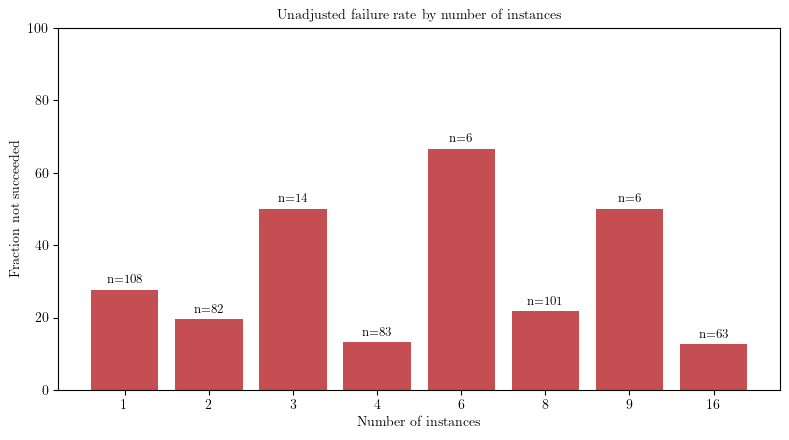

In [21]:
by_instances = defaultdict(lambda: {'files': 0, 'failures': 0})
for row in rows:
    instances = row['number_of_instances']
    if instances is not None:
        by_instances[instances]['files'] += 1
        by_instances[instances]['failures'] += int(row['failed'])

summary = []
for instances, values in sorted(by_instances.items()):
    files, failures = values['files'], values['failures']
    summary.append((instances, files, failures, failures / files))

print(f"{'instances':>10} {'files':>7} {'failures':>10} {'failure rate':>14}")
for instances, files, failures, rate in summary:
    print(f'{instances:>10.0f} {files:>7} {failures:>10} {rate:>13.1%}')

labels = [str(int(instances)) for instances, _, _, _ in summary]
rates = [rate for _, _, _, rate in summary]
sizes = [files for _, files, _, _ in summary]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(labels, rates, color='#c44e52')
ax.bar_label(bars, labels=[f'n={size}' for size in sizes], padding=3, fontsize=9)
ax.set(ylim=(0, 1), xlabel='Number of instances', ylabel='Fraction not succeeded',
       title='Unadjusted failure rate by number of instances')
ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
fig.savefig(PLOTS_DIR / 'failure_rate_by_instances.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
# A chi-square test asks whether failure outcome and instance count are independent.
# It is descriptive here: small cells and confounding can make its p-value misleading.
instance_levels = sorted(by_instances)
contingency = np.array([
    [by_instances[level]['failures'], by_instances[level]['files'] - by_instances[level]['failures']]
    for level in instance_levels
])
print('Rows are instance counts; columns are [not succeeded, succeeded]:')
print(contingency)

chi2, p_value, dof, expected = chi2_contingency(contingency)
print(f'Chi-square = {chi2:.3f}, dof = {dof}, p = {p_value:.4g}')
print(f'Smallest expected cell count = {expected.min():.2f}')

Rows are instance counts; columns are [not succeeded, succeeded]:
[[30 78]
 [16 66]
 [ 7  7]
 [11 72]
 [ 4  2]
 [22 79]
 [ 3  3]
 [ 8 55]]
Chi-square = 25.536, dof = 7, p = 0.0006094
Smallest expected cell count = 1.31


## Check confounding

A raw difference may reflect different systems, functionals, or rank counts. The following comparison breaks the result down by system and functional; it also prints the median MPI rank count in every stratum.

system     functional  instances   files   failure rate   median ranks
BaTiO3     HSE06               1      11        100.0%            900
BaTiO3     HSE06               2       8        100.0%            256
BaTiO3     HSE06               3       7        100.0%           1080
BaTiO3     HSE06               4       6        100.0%            512
BaTiO3     HSE06               6       4        100.0%            768
BaTiO3     HSE06               8      10        100.0%           2048
BaTiO3     HSE06               9       3        100.0%           1080
water      HSE06               1      38         21.1%            128
water      HSE06               2      42         19.0%            256
water      HSE06               4      46          8.7%            512
water      HSE06               8      51         23.5%           1024
water      HSE06              16      49         16.3%           2048
water      revPBE0             1      59         18.6%            256
water      revPBE0 

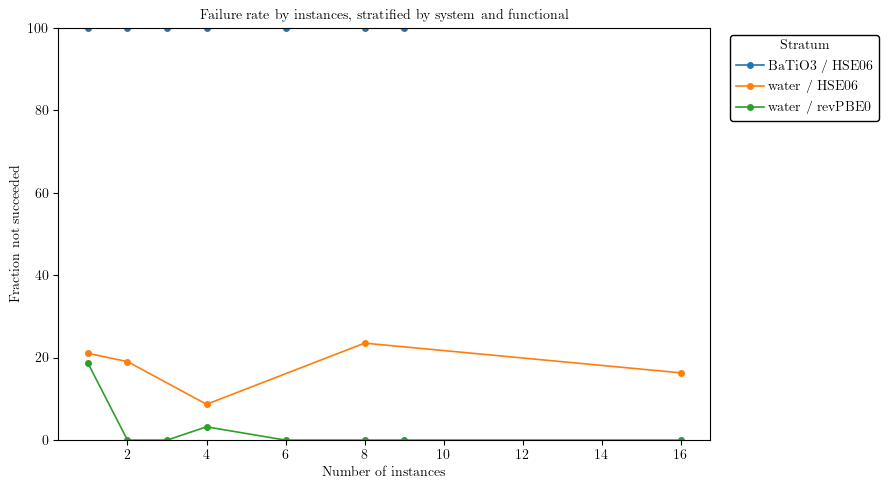

In [23]:
strata = defaultdict(lambda: {'files': 0, 'failures': 0, 'ranks': []})
for row in rows:
    if row['number_of_instances'] is None:
        continue
    key = (row['system'], row['functional'], row['number_of_instances'])
    strata[key]['files'] += 1
    strata[key]['failures'] += int(row['failed'])
    if row['number_of_ranks'] is not None:
        strata[key]['ranks'].append(row['number_of_ranks'])

print(f"{'system':<10} {'functional':<10} {'instances':>10} {'files':>7} {'failure rate':>14} {'median ranks':>14}")
for (system, functional, instances), values in sorted(strata.items()):
    rate = values['failures'] / values['files']
    median_ranks = np.median(values['ranks']) if values['ranks'] else np.nan
    print(f'{system:<10} {functional:<10} {instances:>10.0f} {values["files"]:>7} {rate:>13.1%} {median_ranks:>14.0f}')

plot_groups = defaultdict(list)
for (system, functional, instances), values in strata.items():
    plot_groups[(system, functional)].append((instances, values['failures'] / values['files']))

fig, ax = plt.subplots(figsize=(9, 5))
for (system, functional), points in sorted(plot_groups.items()):
    points.sort()
    ax.plot(*zip(*points), marker='o', label=f'{system} / {functional}')
ax.set(ylim=(0, 1), xlabel='Number of instances', ylabel='Fraction not succeeded',
       title='Failure rate by instances, stratified by system and functional')
ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
ax.legend(title='Stratum', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'failure_rate_by_instances_stratified.png', dpi=300, bbox_inches='tight')
plt.show()

## Instance-count distributions by system and functional

Each panel uses the same discrete instance-count bins. The two overlaid histograms show the number of successful and failed output files in that system/functional stratum.

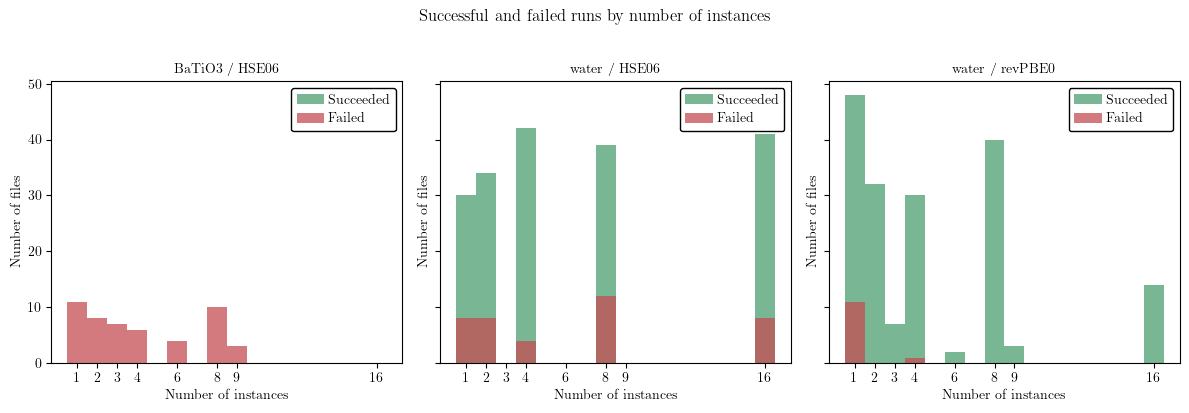

In [24]:
# Faceted histograms: successes and failures use the same bins in every panel.
facet_rows = [row for row in rows if row['number_of_instances'] is not None]
facets = sorted({(row['system'], row['functional']) for row in facet_rows})
instance_values = [row['number_of_instances'] for row in facet_rows]
bins = np.arange(min(instance_values) - 0.5, max(instance_values) + 1.5, 1)

ncols = 3
nrows = int(np.ceil(len(facets) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, (system, functional) in zip(axes, facets):
    group = [row for row in facet_rows if (row['system'], row['functional']) == (system, functional)]
    successful = [row['number_of_instances'] for row in group if not row['failed']]
    failed = [row['number_of_instances'] for row in group if row['failed']]
    ax.hist(successful, bins=bins, color='#4c9f70', alpha=0.75, label='Succeeded')
    ax.hist(failed, bins=bins, color='#c44e52', alpha=0.75, label='Failed')
    ax.set_title(f'{system} / {functional}')
    ax.set_xlabel('Number of instances')
    ax.set_ylabel('Number of files')
    ax.set_xticks(sorted(set(instance_values)))
    ax.legend()

for ax in axes[len(facets):]:
    ax.remove()

fig.suptitle('Successful and failed runs by number of instances', y=1.02)
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'instances_by_outcome_system_functional.png', dpi=300, bbox_inches='tight')
plt.show()

## Instances versus total MPI tasks

This correlation-style scatter plot uses `number_of_ranks` as the total MPI-task count. It has one panel per system, functional, and atom count; colors encode `number_of_nodes`, while circles mark successful jobs and large X markers mark failed jobs.

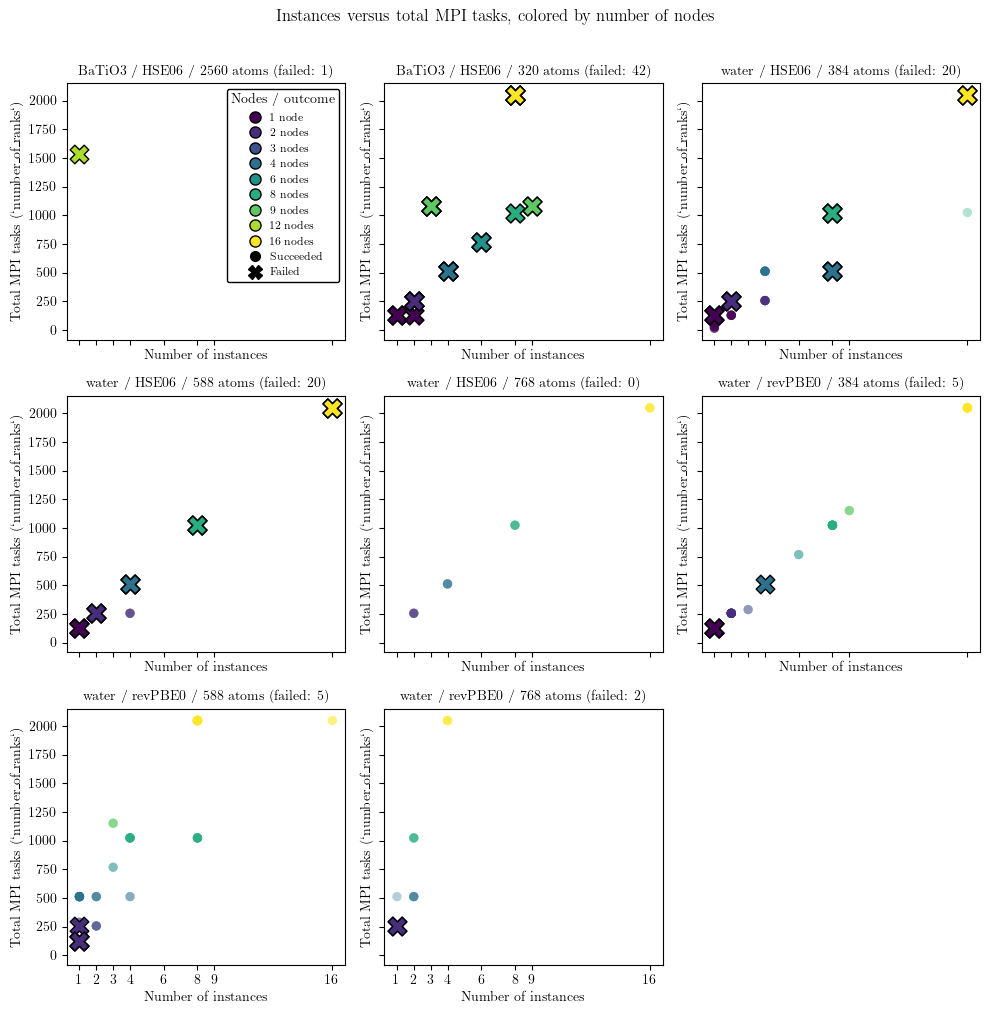

In [28]:
# Each point is one output file with all three allocation fields available.
allocation_rows = [
    row for row in rows
    if row['number_of_instances'] is not None
    and row['number_of_ranks'] is not None
    and row['number_of_nodes'] is not None
]
allocation_facets = sorted({(row['system'], row['functional'], row['number_of_atoms']) for row in allocation_rows})
node_levels = sorted({row['number_of_nodes'] for row in allocation_rows})
colour_map = plt.get_cmap('viridis', len(node_levels))
node_colours = {nodes: colour_map(index) for index, nodes in enumerate(node_levels)}

ncols = 3
nrows = int(np.ceil(len(allocation_facets) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(10,10), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, (system, functional, number_of_atoms) in zip(axes, allocation_facets):
    group = [
        row for row in allocation_rows
        if (row['system'], row['functional'], row['number_of_atoms']) == (system, functional, number_of_atoms)
    ]
    # Plot successes first, then failures over them, so failures remain visible
    # even when jobs share identical instance/task coordinates.
    for nodes in node_levels:
        points = [
            row for row in group
            if row['number_of_nodes'] == nodes and not row['failed']
        ]
        if points:
            ax.scatter(
                [row['number_of_instances'] for row in points],
                [row['number_of_ranks'] for row in points],
                color=node_colours[nodes], marker='o', alpha=0.35, s=45,
                edgecolors='none', zorder=1,
            )
    for nodes in node_levels:
        points = [
            row for row in group
            if row['number_of_nodes'] == nodes and row['failed']
        ]
        if points:
            ax.scatter(
                [row['number_of_instances'] for row in points],
                [row['number_of_ranks'] for row in points],
                color=node_colours[nodes], marker='X', alpha=1.0, s=180,
                edgecolors='black', linewidths=1.0, zorder=5,
            )
    failed_count = sum(row['failed'] for row in group)
    ax.set_title(f'{system} / {functional} / {number_of_atoms} atoms (failed: {failed_count})')
    ax.set_xlabel('Number of instances')
    ax.set_ylabel('Total MPI tasks (`number_of_ranks`)')
    ax.set_xticks(sorted({row['number_of_instances'] for row in allocation_rows}))

for ax in axes[len(allocation_facets):]:
    ax.remove()

from matplotlib.lines import Line2D
node_handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=node_colours[nodes],
           label=f'{int(nodes)} node' + ('s' if nodes != 1 else ''), markersize=8)
    for nodes in node_levels
]
outcome_handles = [
    Line2D([0], [0], marker='o', color='black', linestyle='None', label='Succeeded', markersize=7),
    Line2D([0], [0], marker='X', color='black', linestyle='None', label='Failed', markersize=10),
]
axes[0].legend(handles=node_handles + outcome_handles, title='Nodes / outcome', fontsize=8)
fig.suptitle('Instances versus total MPI tasks, colored by number of nodes', y=1.01)
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'instances_vs_mpi_tasks_by_nodes_and_outcome.png', dpi=300, bbox_inches='tight')
plt.show()

## Leading basis dimension versus MPI tasks

This plot uses FHI-aims' `Maximum number of basis functions`, the extended-basis leading dimension reported in the structure-dependent array-size summary. Colors encode total available memory per allocated node from `general_nodes.csv`; circles are successful jobs and large X markers are failed jobs.

In [ ]:
matrix_rows = [
    row for row in rows
    if row['maximum_number_of_basis_functions'] is not None
    and row['number_of_ranks'] is not None
    and row['available_memory_per_node_gb'] is not None
]
matrix_facets = sorted({(row['system'], row['functional']) for row in matrix_rows})
memory_levels = sorted({row['available_memory_per_node_gb'] for row in matrix_rows})
colour_map = plt.get_cmap('viridis', len(memory_levels))
memory_colours = {memory: colour_map(index) for index, memory in enumerate(memory_levels)}

# Columns are system/functional combinations; rows split the outcome.
fig, axes = plt.subplots(2, len(matrix_facets), figsize=(15, 10), sharey=True)
axes = np.atleast_2d(axes)

for column, (system, functional) in enumerate(matrix_facets):
    group = [
        row for row in matrix_rows
        if (row['system'], row['functional']) == (system, functional)
    ]
    for row_index, (failed, outcome, marker, alpha, size) in enumerate([
        (False, 'Succeeded', 'o', 0.55, 55),
        (True, 'Failed', 'X', 1.0, 170),
    ]):
        ax = axes[row_index, column]
        for memory in memory_levels:
            points = [
                row for row in group
                if row['available_memory_per_node_gb'] == memory and row['failed'] == failed
            ]
            if points:
                ax.scatter(
                    [row['maximum_number_of_basis_functions'] for row in points],
                    [row['number_of_ranks'] for row in points],
                    color=memory_colours[memory], marker=marker, alpha=alpha, s=size,
                    edgecolors='black' if failed else 'none', linewidths=1.0 if failed else 0,
                )
        ax.set_title(f'{system} / {functional} — {outcome}')
        ax.set_xlabel('Maximum number of basis functions')
        ax.set_ylabel('Total MPI tasks (`number_of_ranks`)')

from matplotlib.lines import Line2D
memory_handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=memory_colours[memory],
           label=f'{memory:g} GB/node', markersize=8)
    for memory in memory_levels
]
axes[0, 0].legend(handles=memory_handles, title='Available memory', fontsize=8)
fig.suptitle('Leading basis dimension versus MPI tasks, colored by node memory', y=1.01)
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'maximum_basis_functions_vs_mpi_tasks_by_memory_and_outcome.png', dpi=300, bbox_inches='tight')
plt.show()

## Water, 588 atoms: does revPBE0 really fail less often?

The allocation scatter plot excludes any run without a reported instance count, MPI-task count, or node count. A job can fail before FHI-aims prints those values. The following analysis compares HSE06 and revPBE0 without silently dropping those failures, and removes byte-identical copied outputs before comparing campaign-level rates.

In [ ]:
# First quantify selection bias in the allocation scatter plot.
water_588 = [
    row for row in rows
    if row['system'] == 'water'
    and row['number_of_atoms'] == '588'
    and row['functional'] in {'HSE06', 'revPBE0'}
]
allocation_fields = ('number_of_instances', 'number_of_ranks', 'number_of_nodes')
failure_overview = {}

for functional in ('HSE06', 'revPBE0'):
    group = [row for row in water_588 if row['functional'] == functional]
    failures = [row for row in group if row['failed']]
    visible = [row for row in failures if all(row[field] is not None for field in allocation_fields)]
    missing = [row for row in failures if row not in visible]
    failure_overview[functional] = {
        'files': len(group),
        'failures': len(failures),
        'visible_failures': len(visible),
        'missing_allocation': len(missing),
    }

print(f"{'functional':<10} {'files':>7} {'failures':>10} {'shown in scatter':>17} {'missing allocation':>20}")
for functional, values in failure_overview.items():
    print(f"{functional:<10} {values['files']:>7} {values['failures']:>10} {values['visible_failures']:>17} {values['missing_allocation']:>20}")

labels = list(failure_overview)
visible = [failure_overview[label]['visible_failures'] for label in labels]
missing = [failure_overview[label]['missing_allocation'] for label in labels]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(labels, visible, color='#c44e52', label='Shown in allocation scatter')
ax.bar(labels, missing, bottom=visible, color='#9e9e9e', label='Excluded: allocation data missing')
ax.set(ylabel='Failed CSV rows', title='Water, 588 atoms: failures omitted from the allocation scatter')
ax.legend()
fig.savefig(PLOTS_DIR / 'water_588_failure_metadata_completeness.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Deduplicate copied output files, then compare campaigns rather than pooled rows.
from hashlib import sha256

unique_campaign_runs = defaultdict(dict)
for row in water_588:
    output_path = Path(row['bundle_filepath'])
    campaign = output_path.parts[2]  # outputs/water/<campaign>/...
    digest = sha256(output_path.read_bytes()).hexdigest()
    unique_campaign_runs[(row['functional'], campaign)].setdefault(digest, row)

campaigns = sorted({campaign for _, campaign in unique_campaign_runs})
campaign_results = {}
print(f"{'campaign':<38} {'HSE06':>12} {'revPBE0':>12}")
for campaign in campaigns:
    summary = []
    for functional in ('HSE06', 'revPBE0'):
        runs = list(unique_campaign_runs[(functional, campaign)].values())
        failures = sum(row['failed'] for row in runs)
        campaign_results[(functional, campaign)] = (failures, len(runs))
        summary.append(f'{failures}/{len(runs)}')
    print(f'{campaign:<38} {summary[0]:>12} {summary[1]:>12}')

x = np.arange(len(campaigns))
width = 0.38
fig, ax = plt.subplots(figsize=(12, 5))
for offset, functional, colour in [(-width / 2, 'HSE06', '#4c72b0'), (width / 2, 'revPBE0', '#dd8452')]:
    rates = [
        failures / runs if runs else np.nan
        for failures, runs in (campaign_results[(functional, campaign)] for campaign in campaigns)
    ]
    ax.bar(x + offset, rates, width, label=functional, color=colour)
ax.set(xticks=x, xticklabels=campaigns, ylim=(0, 1), ylabel='Failure rate',
       title='Water, 588 atoms: campaign-level failure rate (identical outputs deduplicated)')
ax.tick_params(axis='x', rotation=25)
ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
ax.legend()
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'water_588_campaign_failure_rates.png', dpi=300, bbox_inches='tight')
plt.show()

The pooled scatter plot alone cannot establish that revPBE0 is more robust. It may omit more early revPBE0 failures, and the two functionals do not have equal samples in every campaign. Compare only matched campaigns with the same input, allocation, and execution environment before attributing a difference to the functional itself.

## Optional adjusted model

If you install `pandas` and `statsmodels`, this logistic regression estimates the association of instance count with failure after adjusting for system, functional, and `log2(number_of_ranks)`. Treat it as exploratory: runs were not randomly assigned to instance count and the CSV cannot capture every operational factor.

In [26]:
try:
    import pandas as pd
    import statsmodels.formula.api as smf
except ImportError:
    print('Optional: install pandas and statsmodels to run this adjusted model.')
else:
    model_data = pd.DataFrame(rows)
    model_data = model_data.dropna(subset=['number_of_instances', 'number_of_ranks'])
    model_data = model_data.loc[model_data['number_of_ranks'] > 0].copy()
    model_data['log2_ranks'] = np.log2(model_data['number_of_ranks'])
    model = smf.logit(
        'failed ~ number_of_instances + log2_ranks + C(system) + C(functional)',
        data=model_data,
    ).fit(disp=False)
    adjusted = pd.DataFrame({
        'odds_ratio': np.exp(model.params),
        'p_value': model.pvalues,
        'ci_low': np.exp(model.conf_int()[0]),
        'ci_high': np.exp(model.conf_int()[1]),
    })
    display(adjusted.loc[['number_of_instances', 'log2_ranks']].style.format('{:.3g}'))

Optional: install pandas and statsmodels to run this adjusted model.


## Interpretation

A consistent rate difference across comparable strata, together with an adjusted instance-count effect, is stronger evidence of an association. If the difference disappears after stratifying or adjusting for ranks, it is more likely explained by the way runs were configured rather than by instance count itself.